# Applied Statistics: Analysis of the Iris Dataset

## Introduction

This notebook investigates the distributions and relationships of petal measurements in the Iris dataset. It uses descriptive statistics, visualisations, correlation analysis, independent-samples t-tests, and one-way analysis of variance (ANOVA) to explore differences between three iris species: setosa, versicolor, and virginica.

The analysis aims to assess whether petal length can reasonably be modelled using a normal distribution, quantify the relationship between petal length and petal width, and determine whether the mean petal measurements differ between species.

The analysis is conducted using Python, with NumPy, pandas, Matplotlib, Seaborn, and SciPy.

In [1]:
# import Numpy for numerical operations 
import numpy as np 
# import Matplotlib for plotting
import matplotlib.pyplot as plt 
# import Scikit-learn for machine learning
import sklearn as skl 
# import Scikit-learn datasets
from sklearn import datasets 
# import Pandas for data manipulation and analysis
import pandas as pd 
# import Seaborn for statistical data visualization
import seaborn as sns 
# import stats from scipy for statistical analysis
from scipy import stats

In [2]:
# import Iris dataset as a pandas DataFrame
iris = skl.datasets.load_iris(as_frame=True)

In [3]:
# print the shape of the data
print(iris.data.shape)

(150, 4)


In [4]:
# create a pandas DataFrame from the Iris dataset. Set the column names to the feature names
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)

In [5]:
# explore the first 5 lines of the dataframe
iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [6]:
# explore how many columns and rows there are in the dataset
iris_df.shape

(150, 4)

In [7]:
# generate a statistical summary of the dataset
iris_df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [8]:
# create variables to store the four different features of iris flower
sepal_length = iris_df["sepal length (cm)"]
sepal_width = iris_df["sepal width (cm)"]
petal_length = iris_df["petal length (cm)"]
petal_width = iris_df["petal width (cm)"]

In [9]:
# explore the different types of species in the dataset and their counts
np.unique(iris.target, return_counts= True)

(array([0, 1, 2]), array([50, 50, 50], dtype=int64))

In [10]:
# print target names
print(iris.target_names)

['setosa' 'versicolor' 'virginica']


In [11]:
# store data of the three iris species in corresponding variables
setosa = iris["data"][iris["target"]==0]
versicolor = iris["data"][iris["target"]==1]
virginica = iris["data"][iris["target"]==2]

The Iris dataset contains measurements of 150 flowers belonging to three species of Iris flowers: Iris setosa, Iris versicolor and Iris virginica. The measurements recorded for each flower include: sepal length, sepal width, petal length and petal width. 

## Problem 1: Exploring Petal Length

Investigate the distribution of the petal length in the Iris dataset.

Plot a histogram of the petal length of all 150 flowers. On the same plot, superimpose an appropriate normal distribution, using the mean and standard deviation calculated from the data. Create separate histograms for each of the three species, and superimpose an appropriate normal distribution on each.
Report the mean and standard deviation of petal length for the complete dataset and for each species.
Describe and compare the distributions you observe. In particular, discuss whether a normal distribution appears to be a reasonable model for petal length overall and within each species.

In [12]:
# calculate the mean and standard deviation of the petal length
mean_petal_length = np.mean(petal_length)
std_petal_length = np.std(petal_length)
print(f"Mean Petal Length: {mean_petal_length:.2f} cm")
print(f"Standard Deviation of Petal Length: {std_petal_length:.2f} cm")

Mean Petal Length: 3.76 cm
Standard Deviation of Petal Length: 1.76 cm


In [13]:
# calculate the x_min and x_max values for the normal distribution curve
x_min_all = mean_petal_length - 3 * std_petal_length
x_max_all = mean_petal_length + 3 * std_petal_length
print(f"x_min: {x_min_all:.2f} cm")
print(f"x_max: {x_max_all:.2f} cm")

x_min: -1.52 cm
x_max: 9.04 cm


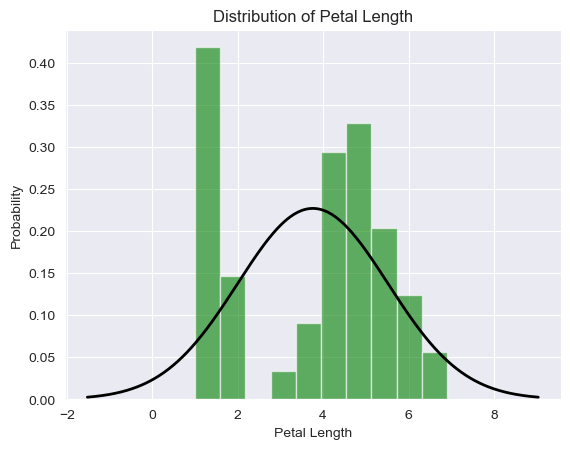

In [27]:
# create a normal distribution bell curve
normal_dist = np.linspace(x_min_all, x_max_all, 400)
plt.hist(petal_length, bins = 10, density=True, alpha=0.6, color='g')
plt.plot(normal_dist, stats.norm.pdf(normal_dist, mean_petal_length, std_petal_length), 'k', linewidth=2)
plt.xlabel('Petal Length')
plt.ylabel('Probability')
plt.title('Distribution of Petal Length')
plt.show()

In [15]:
setosa_petal_length = setosa.iloc[:, 2]
versicolor_petal_length = versicolor.iloc[:, 2]
virginica_petal_length = virginica.iloc[:, 2]

### Iris Setosa Petal Length

In [16]:
# calculate the mean and standard deviation of the petal length for setosa
mean_setosa_petal_length = np.mean(setosa_petal_length)
std_setosa_petal_length = np.std(setosa_petal_length)
print(f"Mean Setosa Petal Length: {mean_setosa_petal_length:.2f} cm")
print(f"Standard Deviation of Setosa Petal Length: {std_setosa_petal_length:.2f} cm")

Mean Setosa Petal Length: 1.46 cm
Standard Deviation of Setosa Petal Length: 0.17 cm


In [17]:
# calculate the x_min and x_max values for the normal distribution curve for setosa
x_min_setosa = mean_setosa_petal_length - 3 * std_setosa_petal_length
x_max_setosa = mean_setosa_petal_length + 3 * std_setosa_petal_length
print(f"x_min_setosa: {x_min_setosa:.2f} cm")
print(f"x_max_setosa: {x_max_setosa:.2f} cm")

x_min_setosa: 0.95 cm
x_max_setosa: 1.98 cm


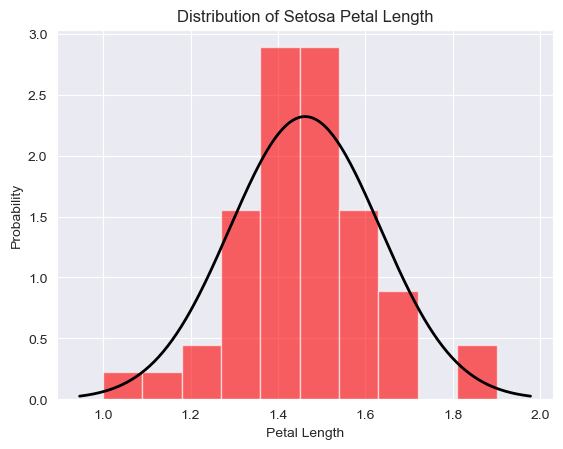

In [28]:
# plot the histogram of the petal length for setosa and superimpose a normal distribution curve
plt.hist(setosa_petal_length, bins = 10, density=True, alpha=0.6, color='r')
normal_dist = np.linspace(x_min_setosa, x_max_setosa, 400)
plt.plot(normal_dist, stats.norm.pdf(normal_dist, mean_setosa_petal_length, std_setosa_petal_length), 'k', linewidth=2)
plt.xlabel('Petal Length')
plt.ylabel('Probability')
plt.title('Distribution of Setosa Petal Length')
plt.show()

### Iris Versicolor Petal Length

In [19]:
# calculate the mean and standard deviation of the petal length for versicolor
mean_versicolor_petal_length = np.mean(versicolor_petal_length)
std_versicolor_petal_length = np.std(versicolor_petal_length)
print(f"Mean Versicolor Petal Length: {mean_versicolor_petal_length:.2f} cm")
print(f"Standard Deviation of Versicolor Petal Length: {std_versicolor_petal_length:.2f} cm")

Mean Versicolor Petal Length: 4.26 cm
Standard Deviation of Versicolor Petal Length: 0.47 cm


In [20]:
# calculate the x_min and x_max values for the normal distribution curve for versicolor
x_min_versicolor = mean_versicolor_petal_length - 3 * std_versicolor_petal_length
x_max_versicolor = mean_versicolor_petal_length + 3 * std_versicolor_petal_length
print(f"x_min_versicolor: {x_min_versicolor:.2f} cm")
print(f"x_max_versicolor: {x_max_versicolor:.2f} cm")

x_min_versicolor: 2.86 cm
x_max_versicolor: 5.66 cm


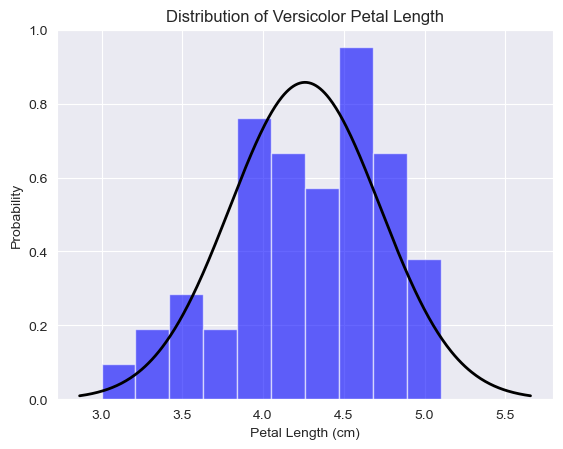

In [30]:
# plot the histogram of the petal length for versicolor and superimpose a normal distribution curve
plt.hist(versicolor_petal_length, bins = 10, density=True, alpha=0.6, color='b')
normal_dist = np.linspace(x_min_versicolor, x_max_versicolor, 400)
plt.plot(normal_dist, stats.norm.pdf(normal_dist, mean_versicolor_petal_length, std_versicolor_petal_length), 'k', linewidth=2)
plt.xlabel('Petal Length (cm)')
plt.ylabel('Probability')
plt.title('Distribution of Versicolor Petal Length')
plt.show()

### Iris Virginica Petal Length

In [22]:
# calculate the mean and standard deviation of the petal length for virginica
mean_virginica_petal_length = np.mean(virginica_petal_length)
std_virginica_petal_length = np.std(virginica_petal_length)
print(f"Mean Virginica Petal Length: {mean_virginica_petal_length:.2f} cm")
print(f"Standard Deviation of Virginica Petal Length: {std_virginica_petal_length:.2f} cm")

Mean Virginica Petal Length: 5.55 cm
Standard Deviation of Virginica Petal Length: 0.55 cm


In [23]:
# calculate the x_min and x_max values for the normal distribution curve for virginica
x_min_virginica = mean_virginica_petal_length - 3 * std_virginica_petal_length
x_max_virginica = mean_virginica_petal_length + 3 * std_virginica_petal_length
print(f"x_min_virginica: {x_min_virginica:.2f} cm")
print(f"x_max_virginica: {x_max_virginica:.2f} cm")

x_min_virginica: 3.91 cm
x_max_virginica: 7.19 cm


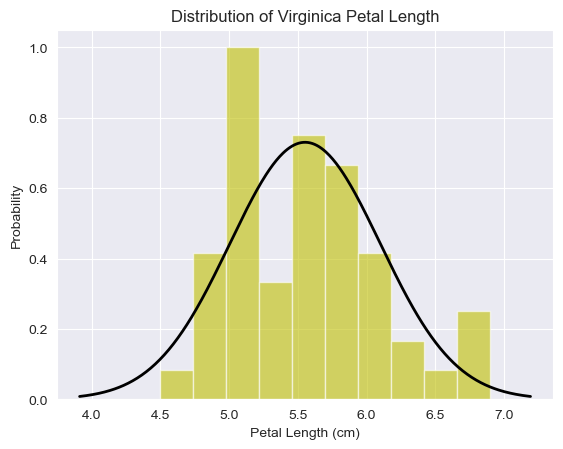

In [31]:
# plot the histogram of the petal length for virginica and superimpose a normal distribution curve
plt.hist(virginica_petal_length, bins = 10, density=True, alpha=0.6, color='y')
normal_dist = np.linspace(x_min_virginica, x_max_virginica, 400)
plt.plot(normal_dist, stats.norm.pdf(normal_dist, mean_virginica_petal_length, std_virginica_petal_length), 'k', linewidth=2)
plt.xlabel('Petal Length (cm)')
plt.ylabel('Probability')
plt.title('Distribution of Virginica Petal Length')
plt.show()

### Comparison of Distributions

In [25]:
# create a table to compare the mean and standard deviation of petal length for each species
comparison_table = pd.DataFrame({
    "Species": ["Setosa", "Versicolor", "Virginica"],
    "Mean Petal Length (cm)": [mean_setosa_petal_length, mean_versicolor_petal_length, mean_virginica_petal_length],
    "Standard Deviation of Petal Length (cm)": [std_setosa_petal_length, std_versicolor_petal_length, std_virginica_petal_length]
})
comparison_table

,Species,Mean Petal Length (cm),Standard Deviation of Petal Length (cm)
0,Setosa,1.462,0.171919
1,Versicolor,4.260,0.465188
2,Virginica,5.552,0.546348


The distribution of petal length across all 150 flowers is not approximately normal. The histogram shows distinct clusters of observations, corresponding to differences in petal length between the three iris species. Consequently, a single normal distribution does not adequately represent the combined dataset.

When the species are analysed separately, their distributions are more concentrated around their respective means.

*Setosa* has the shortest petals on average (1.46 cm) and the smallest standard deviation (0.17 cm), indicating relatively little variation in petal length. *Versicolor* has a higher mean (4.26 cm) and greater variability (0.47 cm), while *virginica* has the longest petals on average (5.55 cm) and the greatest within-species variability (0.55 cm).

The species-specific distributions are generally more compatible with a normal model than the combined dataset, although some departures from a symmetric bell-shaped distribution are visible.

Overall, the analysis suggests that a normal distribution may provide a useful approximation within individual species, particularly for *versicolor* and *virginica*, but is not appropriate for modelling petal length across all three species together.

## Problem 2: Correlation Between Petal Length and Petal Width

## Problem 3: Comparing Species Using t-Tests

## Problem 4: Comparing the Species Using ANOVA

## End